# 미션 3_타이타닉 생존 예측

승객 891명의 정보로 생존 여부(`Survived`)를 맞히는 **이진 분류** 문제입니다. 탐색적 분석부터 피처 엔지니어링, 모델 비교, 튜닝, 앙상블, 최종 평가까지 **데이터 누수 없이** 이어지는 파이프라인을 만들었습니다.

| 단계 | 내용 |
| :-- | :-- |
| **0. 데이터 분할** | 맨 처음 20%를 최종 평가용으로 떼어 두고 **마지막에 한 번만** 사용 |
| **1. 탐색적 분석** | 성별·등급·호칭·가족 규모별 생존율 (표본 수 함께 표시) + 통계 검정 |
| **2. 피처 엔지니어링** | 호칭·가족 규모·객실 정보 추출, 호칭 × 등급별 나이 대치 (Pipeline 내부) |
| **3. 전처리 · 기본 모델** | 모델별 전처리 비교, 가족 변수 표현 비교, LR · KNN · Tree 기본 성능 |
| **4. 튜닝 · 앙상블** | 6개 모델 GridSearchCV + **중첩 교차검증**, Voting · Stacking |
| **5. 최종 평가** | 1-SE 규칙으로 모델 선택 → 최종 평가 데이터에서 한 번 확인, 오류 분석 |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from IPython.display import display
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
installed = {f.name for f in font_manager.fontManager.ttflist}
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
BLUE, RED, GRAY = "#2a78d6", "#d03b3b", "#b9b7ae"

---
## 0. 데이터 불러오기와 분할

모델과 설정을 고르는 과정에 쓴 데이터로 최종 점수를 내면 성능이 부풀려집니다. 그래서 **가장 먼저 20%(179명)를 최종 평가용으로 떼어 두고**, 탐색 · 튜닝 · 모델 선택은 나머지 80%(712명)의 **개발 데이터** 안에서만 합니다.

In [2]:
data = pd.read_csv("titanic_train.csv")
dev, holdout = train_test_split(data, test_size=0.2, stratify=data["Survived"], random_state=RANDOM_STATE)
print(f"전체 {len(data)}명 → 개발 {len(dev)}명 · 최종 평가 {len(holdout)}명")
print(f"생존율: 개발 {dev['Survived'].mean():.1%} · 최종 평가 {holdout['Survived'].mean():.1%}")
data.head(3)

전체 891명 → 개발 712명 · 최종 평가 179명
생존율: 개발 38.3% · 최종 평가 38.5%


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [3]:
missing = dev.isna().sum()
pd.DataFrame({"결측 수": missing, "결측률": (missing / len(dev)).map("{:.1%}".format)})[missing > 0]

,결측 수,결측률
Age,137,19.2%
Cabin,552,77.5%
Embarked,2,0.3%


| 컬럼 | 처리 | 이유 |
| :-- | :-- | :-- |
| `Age` (약 20% 결측) | **호칭 × 객실 등급별 중앙값**으로 대치하고, 결측 여부를 `AgeMissing` 변수로 남김 | Master(소년)와 Mr의 나이 차이처럼 집단별 나이가 크게 다름 |
| `Cabin` (약 77% 결측) | 원문은 쓰지 않고 `HasCabin`(객실 기록 여부)과 `Deck`(갑판)만 추출 | 결측률이 높아 임의로 채우면 왜곡이 큼 |
| `Embarked` (2명) | 최빈값 | 결측이 극히 적음 |

모든 대치는 **Pipeline 안에서 학습 fold의 값으로만** 계산합니다. 그래야 교차검증의 검증 fold 정보가 전처리에 섞이지 않습니다.

---
## 1. 피처 엔지니어링과 탐색적 분석

In [4]:
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """정답을 쓰지 않는 파생 변수: train · 최종 평가 · Kaggle test에 같은 함수를 적용해도 누수가 없다."""
    out = df.copy()
    title = out["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip().replace(TITLE_MAP)
    out["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    out["IsAlone"] = out["FamilySize"].eq(1).astype(int)
    out["FamilyGroup"] = pd.cut(out["FamilySize"], [0, 1, 4, 20], labels=["혼자", "2~4명", "5명+"]).astype(str)
    out["HasCabin"] = out["Cabin"].notna().astype(int)
    out["Deck"] = out["Cabin"].str[0].fillna("없음")
    out["FarePerPerson"] = out["Fare"] / out["FamilySize"]
    return out


dev_fe, holdout_fe = add_features(dev), add_features(holdout)
dev_fe[["Name", "Title", "FamilySize", "FamilyGroup", "HasCabin", "Deck", "FarePerPerson"]].head()

,Name,Title,FamilySize,FamilyGroup,HasCabin,Deck,FarePerPerson
692,"Lam, Mr. Ali",Mr,1,혼자,0,없음,56.4958
481,"Frost, Mr. Anthony Wood ""Archie""",Mr,1,혼자,0,없음,0.0000
527,"Farthing, Mr. John",Mr,1,혼자,1,C,221.7792
855,"Aks, Mrs. Sam (Leah Rosen)",Mrs,2,2~4명,0,없음,4.6750
801,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",Mrs,3,2~4명,0,없음,8.7500


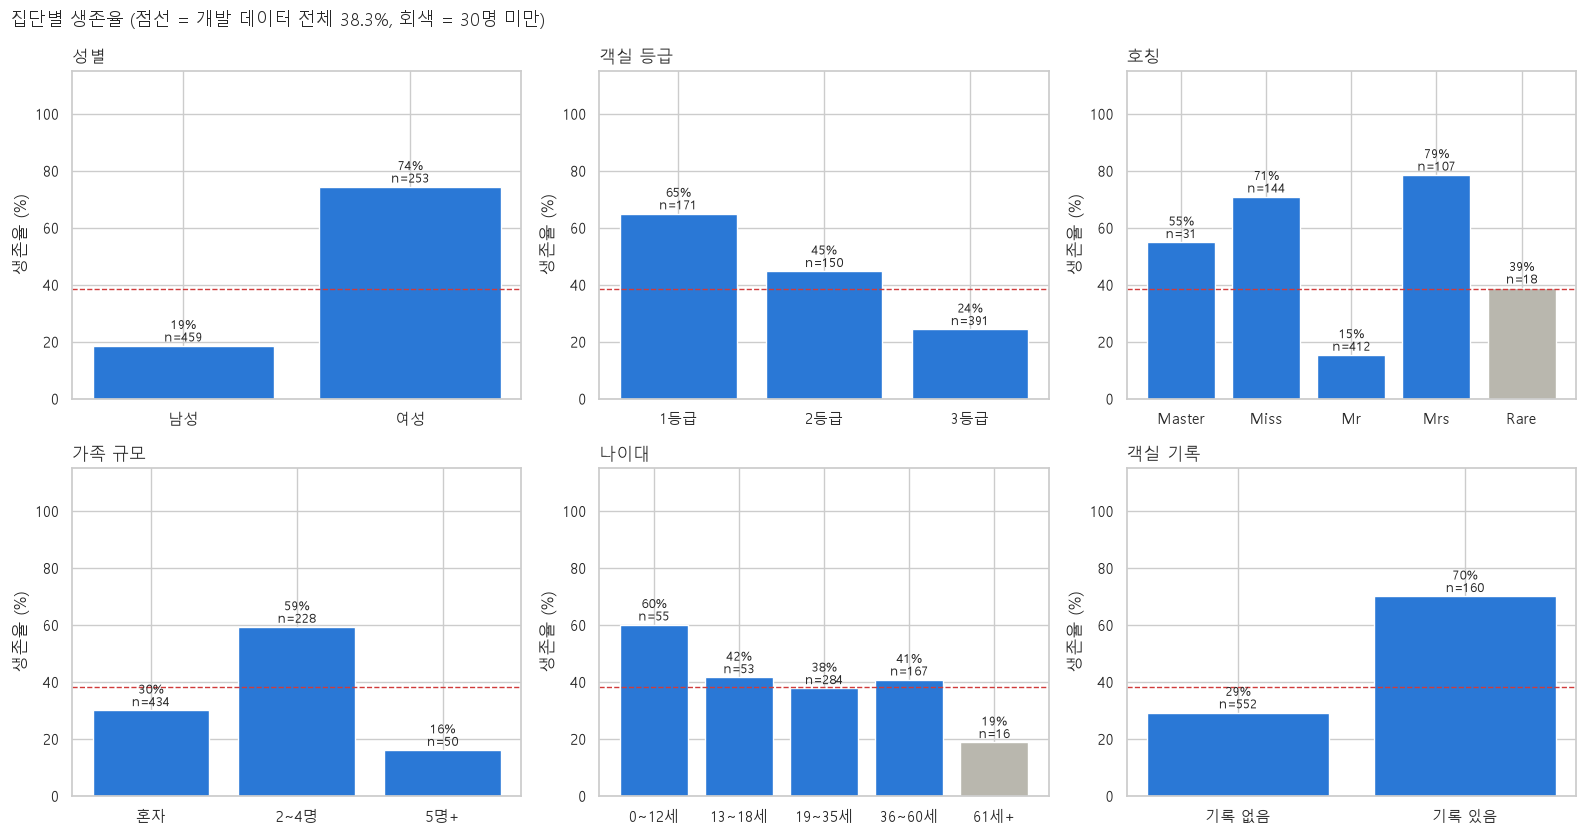

In [5]:
BASE = dev_fe["Survived"].mean()
eda = dev_fe.assign(
    AgeBand=pd.cut(dev_fe["Age"], [0, 12, 18, 35, 60, 100], labels=["0~12세", "13~18세", "19~35세", "36~60세", "61세+"]).astype(str).replace("nan", "나이 결측"),
    Pclass=dev_fe["Pclass"].map({1: "1등급", 2: "2등급", 3: "3등급"}),
    Sex=dev_fe["Sex"].map({"male": "남성", "female": "여성"}),
)
panels = {"성별": "Sex", "객실 등급": "Pclass", "호칭": "Title", "가족 규모": "FamilyGroup", "나이대": "AgeBand", "객실 기록": "HasCabin"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (title, col) in zip(axes.ravel(), panels.items()):
    t = eda.groupby(col)["Survived"].agg(생존율="mean", n="size")
    if col == "FamilyGroup":
        t = t.loc[["혼자", "2~4명", "5명+"]]
    if col == "HasCabin":
        t.index = t.index.map({0: "기록 없음", 1: "기록 있음"})
    bars = ax.bar(t.index.astype(str), t["생존율"] * 100, color=[GRAY if n < 30 else BLUE for n in t["n"]])
    for bar, rate, n in zip(bars, t["생존율"], t["n"]):
        ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1.5, f"{rate:.0%}\nn={n}", ha="center", fontsize=9)
    ax.axhline(BASE * 100, color=RED, linestyle="--", linewidth=1)
    ax.set_ylim(0, 115)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("생존율 (%)")
fig.suptitle(f"집단별 생존율 (점선 = 개발 데이터 전체 {BASE:.1%}, 회색 = 30명 미만)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

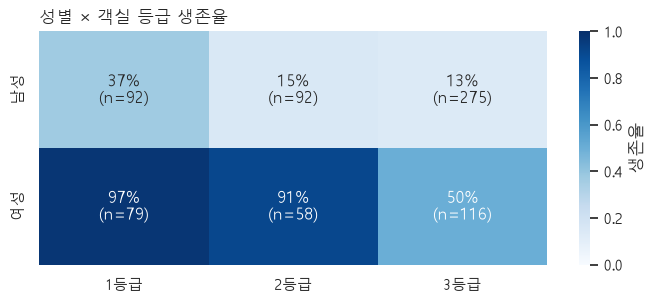

In [6]:
pivot = eda.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc=["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.2))
annot = pivot["mean"].map("{:.0%}".format) + "\n(n=" + pivot["size"].astype(str) + ")"
sns.heatmap(pivot["mean"], annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "생존율"}, ax=ax)
ax.set_title("성별 × 객실 등급 생존율", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

- **성별**이 가장 큰 신호입니다. 여성의 생존율이 남성의 약 4배이며, "여성과 아이 먼저" 원칙과 일치합니다.
- **등급**과 성별이 겹치면 차이가 더 커집니다. 1·2등급 여성은 대부분 살았지만, 3등급 여성은 절반 수준입니다.
- **호칭**은 성별과 나이를 함께 담습니다. 같은 남성이라도 `Master`(소년)는 `Mr`보다 생존율이 훨씬 높습니다.
- **가족 규모**는 2~4명일 때 가장 높고, 혼자이거나 5명 이상이면 낮습니다. 단조로운 관계가 아니라 구간으로 나눈 변수가 유용합니다.

In [7]:
def cramers_v(table):
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / table.to_numpy().sum() / (min(table.shape) - 1))


cat_rows = []
for col in ["Sex", "Title", "Pclass", "HasCabin", "FamilyGroup", "Deck", "Embarked", "IsAlone"]:
    table = pd.crosstab(dev_fe[col].fillna("결측"), dev_fe["Survived"])
    cat_rows.append({"변수": col, "p값": chi2_contingency(table)[1], "Cramér's V": cramers_v(table)})
cat_tests = pd.DataFrame(cat_rows).set_index("변수").sort_values("Cramér's V", ascending=False)

num_rows = []
for col in ["Fare", "FarePerPerson", "Age", "FamilySize"]:
    died, surv = dev_fe.loc[dev_fe["Survived"].eq(0), col].dropna(), dev_fe.loc[dev_fe["Survived"].eq(1), col].dropna()
    u, p = mannwhitneyu(surv, died)
    num_rows.append({"변수": col, "사망 중앙값": died.median(), "생존 중앙값": surv.median(), "p값": p,
                     "효과 크기 (rank-biserial)": 2 * u / (len(surv) * len(died)) - 1})
num_tests = pd.DataFrame(num_rows).set_index("변수")
order = np.argsort(num_tests["p값"].to_numpy())
holm = np.maximum.accumulate([(len(order) - r) * num_tests["p값"].iloc[i] for r, i in enumerate(order)])
num_tests.loc[num_tests.index[order], "Holm 보정 p값"] = np.minimum(holm, 1)

display(cat_tests.style.format({"p값": "{:.1e}", "Cramér's V": "{:.3f}"}).bar(subset=["Cramér's V"], color="#9ecae1"))
display(num_tests.style.format({"사망 중앙값": "{:.1f}", "생존 중앙값": "{:.1f}", "p값": "{:.1e}", "Holm 보정 p값": "{:.1e}", "효과 크기 (rank-biserial)": "{:+.3f}"}))

,p값,Cramér's V
변수,,
Title,2.4e-49,0.573
Sex,4.2e-48,0.546
Deck,2.2e-17,0.368
Pclass,1.9e-19,0.348
HasCabin,2.0e-20,0.347
FamilyGroup,6.1e-15,0.303
IsAlone,1.4e-08,0.213
Embarked,2.0e-06,0.203


,사망 중앙값,생존 중앙값,p값,효과 크기 (rank-biserial),Holm 보정 p값
변수,,,,,
Fare,10.5,26.0,6.9e-20,+0.406,2.8e-19
FarePerPerson,7.9,13.0,2.4e-14,+0.339,7.3e-14
Age,28.2,29.0,2.2e-01,-0.060,2.2e-01
FamilySize,1.0,2.0,1.7e-06,+0.187,3.4e-06


- 범주형 변수에서는 **호칭 · 성별**의 관련성이 압도적입니다(Cramér's V 0.55~0.57). **갑판 · 객실 등급 · 객실 기록 여부**가 0.35 안팎으로 뒤를 잇습니다.
- 수치형 변수에서는 **운임**의 효과 크기가 가장 큽니다(생존자 중앙값 26.0 vs 사망자 10.5).
- **나이**는 단독으로는 유의하지 않습니다(Holm 보정 p = 0.22). 하지만 0~12세의 생존율은 60%로 높습니다. 나이는 선형 관계가 아니라 **아이인가 아닌가**로 작용하며, 이 정보는 호칭 `Master`가 함께 담고 있습니다.

---
## 2. 전처리 파이프라인과 기본 모델

In [8]:
class TitlePclassAgeImputer(BaseEstimator, TransformerMixin):
    """학습 fold에서 구한 '호칭 × 객실 등급' 중앙값으로 Age를 채우고 결측 여부를 남긴다."""

    def fit(self, X, y=None):
        self.group_median_ = X.groupby(["Title", "Pclass"])["Age"].median()
        self.title_median_ = X.groupby("Title")["Age"].median()
        self.global_median_ = X["Age"].median()
        return self

    def transform(self, X):
        X = X.copy()
        miss = X["Age"].isna()
        by_group = pd.Series([self.group_median_.get(k, np.nan) for k in zip(X["Title"], X["Pclass"])], index=X.index)
        X.loc[miss, "Age"] = by_group[miss].fillna(X.loc[miss, "Title"].map(self.title_median_)).fillna(self.global_median_)
        X["AgeMissing"] = miss.astype(int)
        return X


NUM = ["Age", "Fare", "FarePerPerson", "SibSp", "Parch", "FamilySize", "AgeMissing"]
CAT = ["Pclass", "Sex", "Embarked", "Title", "FamilyGroup", "IsAlone", "HasCabin", "Deck"]
X_dev, y_dev = dev_fe[[c for c in NUM if c != "AgeMissing"] + CAT], dev_fe["Survived"]
X_hold, y_hold = holdout_fe[X_dev.columns], holdout_fe["Survived"]


def make_pipe(model, scaler=StandardScaler(), num=None, cat=None):
    """거리·선형 모델은 스케일링, 트리 모델은 scaler=None으로 스케일링 생략 (num/cat 기본값 = 현재 NUM/CAT)"""
    num, cat = num or NUM, cat or CAT
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", clone(scaler))] if scaler is not None else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))]), cat),
    ])
    return Pipeline([("age", TitlePclassAgeImputer()), ("prep", prep), ("model", model)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_eval(pipe, X=X_dev):
    s = cross_validate(pipe, X, y_dev, cv=cv, scoring=["accuracy", "roc_auc"], return_train_score=True, n_jobs=-1)
    return {"CV 정확도": s["test_accuracy"].mean(), "표준편차": s["test_accuracy"].std(), "CV ROC-AUC": s["test_roc_auc"].mean(),
            "학습-CV 차이": s["train_accuracy"].mean() - s["test_accuracy"].mean()}


FMT = {"CV 정확도": "{:.3f}", "표준편차": "{:.3f}", "CV ROC-AUC": "{:.3f}", "학습-CV 차이": "{:+.3f}"}
print("개발 데이터:", X_dev.shape, "| 최종 평가 데이터:", X_hold.shape)

개발 데이터: (712, 14) | 최종 평가 데이터: (179, 14)


### 2-1. 가족 정보는 어떤 형태로 넣는 것이 좋은가

`SibSp`·`Parch` 원본, 합친 `FamilySize`, 구간화한 `FamilyGroup`, `IsAlone`은 모두 같은 정보를 다르게 표현합니다. 하나만 남겼을 때를 비교했습니다.

In [9]:
base_num = ["Age", "Fare", "FarePerPerson", "AgeMissing"]
base_cat = ["Pclass", "Sex", "Embarked", "Title", "HasCabin", "Deck"]
family_sets = {
    "SibSp + Parch": (["SibSp", "Parch"], []),
    "FamilySize": (["FamilySize"], []),
    "FamilyGroup (구간)": ([], ["FamilyGroup"]),
    "IsAlone": ([], ["IsAlone"]),
    "전부 사용": (["SibSp", "Parch", "FamilySize"], ["FamilyGroup", "IsAlone"]),
}
rows = []
for set_name, (fnum, fcat) in family_sets.items():
    for model_name, model, scaler in [("로지스틱 회귀", LogisticRegression(max_iter=2000), StandardScaler()),
                                      ("랜덤 포레스트", RandomForestClassifier(300, max_depth=6, random_state=RANDOM_STATE), None)]:
        pipe = make_pipe(model, scaler, num=base_num + fnum, cat=base_cat + fcat)
        rows.append({"가족 변수": set_name, "모델": model_name, "CV 정확도": cv_eval(pipe)["CV 정확도"]})
family_table = pd.DataFrame(rows).pivot(index="가족 변수", columns="모델", values="CV 정확도")
family_table.style.format("{:.3f}").highlight_max(axis=0, color="#d4edda")

모델,랜덤 포레스트,로지스틱 회귀
가족 변수,,
FamilyGroup (구간),0.827,0.830
FamilySize,0.830,0.830
IsAlone,0.823,0.816
SibSp + Parch,0.820,0.829
전부 사용,0.823,0.829


가족 정보를 어떻게 표현해도 CV 정확도 차이는 **0.014 이내**입니다. `FamilySize` 하나만 쓸 때 두 모델 모두 0.830으로 **가장 높거나 같았습니다.** 성능이 같다면 단순한 쪽을 택해, 이후에는 `FamilySize`만 사용합니다.

In [10]:
# 같은 성능이면 단순한 쪽: 가족 정보는 FamilySize 하나로 표현
NUM = base_num + ["FamilySize"]
CAT = base_cat
print("최종 입력 변수 —", "수치형:", NUM, "| 범주형:", CAT)

최종 입력 변수 — 수치형: ['Age', 'Fare', 'FarePerPerson', 'AgeMissing', 'FamilySize'] | 범주형: ['Pclass', 'Sex', 'Embarked', 'Title', 'HasCabin', 'Deck']


### 2-2. 모델에 맞는 전처리

- **KNN**은 거리로 이웃을 찾고, **로지스틱 회귀**는 가중합으로 계산합니다. 그래서 운임(0~500)처럼 큰 단위의 변수가 결과를 지배하지 않도록 **스케일링이 필요**합니다.
- **트리**는 한 변수의 순서로만 나누므로 스케일링이 의미가 없습니다.

세 가지 스케일러를 비교했습니다.

In [11]:
rows = []
for model_name, model in {"로지스틱 회귀": LogisticRegression(max_iter=2000), "KNN (k=11)": KNeighborsClassifier(11)}.items():
    for scaler_name, scaler in {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler(), "스케일링 없음": None}.items():
        rows.append({"모델": model_name, "스케일러": scaler_name, **cv_eval(make_pipe(model, scaler))})
scaler_table = pd.DataFrame(rows).set_index(["모델", "스케일러"])
scaler_table.style.format(FMT).highlight_max(subset=["CV 정확도"], color="#d4edda")

**KNN**은 스케일링을 빼면 정확도가 0.80 → 0.74로 크게 떨어집니다. 운임처럼 단위가 큰 변수가 거리를 지배하기 때문입니다. **로지스틱 회귀**는 스케일러와 상관없이 0.83으로 거의 같습니다. 그래도 계수 비교와 학습 안정성을 위해 StandardScaler를 기본으로 씁니다.

### 2-3. 기본 모델 비교 (튜닝 전)

In [12]:
baseline = {
    "로지스틱 회귀": make_pipe(LogisticRegression(max_iter=2000)),
    "KNN (k=11)": make_pipe(KNeighborsClassifier(11)),
    "결정 트리 (깊이 제한 없음)": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), None),
    "결정 트리 (깊이 4)": make_pipe(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), None),
}
baseline_table = pd.DataFrame({name: cv_eval(pipe) for name, pipe in baseline.items()}).T
baseline_table.style.format(FMT)

,CV 정확도,표준편차,CV ROC-AUC,학습-CV 차이
로지스틱 회귀,0.830,0.020,0.872,+0.012
KNN (k=11),0.801,0.016,0.862,+0.033
결정 트리 (깊이 제한 없음),0.787,0.032,0.773,+0.202
결정 트리 (깊이 4),0.826,0.037,0.873,+0.040


깊이를 제한하지 않은 결정 트리는 **학습 데이터를 거의 외우지만**(학습-CV 차이가 큼) 검증 성능은 가장 낮습니다. 깊이를 4로 제한하면 차이가 크게 줄어듭니다.

트리는 데이터가 조금만 바뀌어도 판단이 크게 흔들립니다. 아래에서 **겹치는 부분이 많은 두 학습 표본**으로 같은 트리를 만들고, 같은 승객들에 대한 예측을 비교했습니다.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
pool, probe = np.arange(612), np.arange(612, len(X_dev))
sample_a, sample_b = rng.choice(pool, 550, replace=False), rng.choice(pool, 550, replace=False)
deep_tree = make_pipe(DecisionTreeClassifier(min_samples_leaf=2, random_state=RANDOM_STATE), None)
pred_a = clone(deep_tree).fit(X_dev.iloc[sample_a], y_dev.iloc[sample_a]).predict(X_dev.iloc[probe])
pred_b = clone(deep_tree).fit(X_dev.iloc[sample_b], y_dev.iloc[sample_b]).predict(X_dev.iloc[probe])
print(f"두 학습 표본의 공통 승객: {len(set(sample_a) & set(sample_b))} / 550명")
print(f"처음 보는 {len(probe)}명 중 두 트리의 예측이 다른 승객: {(pred_a != pred_b).sum()}명")

두 학습 표본의 공통 승객: 495 / 550명
처음 보는 100명 중 두 트리의 예측이 다른 승객: 13명


학습 데이터가 거의 같은데도 예측이 꽤 달라집니다. 이것이 트리의 **높은 분산**입니다. 서로 다른 표본으로 만든 트리 여러 개의 판단을 모으는 **배깅·랜덤 포레스트**와, 앞 모델의 오차를 순서대로 고치는 **부스팅**이 필요한 이유입니다.

---
## 3. 하이퍼파라미터 튜닝과 앙상블

GridSearchCV가 고른 설정의 CV 점수는 **설정을 고르는 데 이미 쓴 점수**라 낙관적입니다. 그래서 **중첩 교차검증**으로 "튜닝 과정까지 포함한 성능"을 따로 추정했습니다.

- **바깥 5겹**: 성능을 측정합니다.
- **안쪽 5겹**: 설정을 고릅니다.

In [14]:
search_spaces = {
    "로지스틱 회귀": (make_pipe(LogisticRegression(max_iter=3000)),
                {"model__C": [0.03, 0.1, 0.3, 1, 3, 10]}),
    "KNN": (make_pipe(KNeighborsClassifier()),
            {"model__n_neighbors": [5, 9, 13, 17, 21], "model__weights": ["uniform", "distance"]}),
    "결정 트리": (make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), None),
              {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]}),
    "랜덤 포레스트": (make_pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), None),
                {"model__max_depth": [5, 7, None], "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.5]}),
    "그래디언트 부스팅": (make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE), None),
                  {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]}),
    "XGBoost": (make_pipe(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1), None),
                {"model__n_estimators": [200, 400], "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3, 4], "model__subsample": [0.8, 1.0]}),
}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)

tuned, rows = {}, []
for name, (pipe, grid) in search_spaces.items():
    search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="accuracy", n_jobs=-1)
    nested = cross_validate(search, X_dev, y_dev, cv=cv, scoring="accuracy", return_train_score=True)
    search.fit(X_dev, y_dev)
    tuned[name] = search.best_estimator_
    rows.append({"모델": name,
                 "선택된 설정": ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items()),
                 "선택 과정 CV (낙관적)": search.best_score_,
                 "중첩 CV": nested["test_score"].mean(), "표준편차": nested["test_score"].std(),
                 "학습-CV 차이": nested["train_score"].mean() - nested["test_score"].mean()})
tuned_table = pd.DataFrame(rows).set_index("모델").sort_values("중첩 CV", ascending=False)
tuned_table.style.format({"선택 과정 CV (낙관적)": "{:.3f}", "중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})

,선택된 설정,선택 과정 CV (낙관적),중첩 CV,표준편차,학습-CV 차이
모델,,,,,
로지스틱 회귀,C=1,0.826,0.827,0.021,+0.016
결정 트리,"max_depth=5, min_samples_leaf=5",0.827,0.825,0.029,+0.048
랜덤 포레스트,"max_depth=7, max_features=0.5, min_samples_leaf=5",0.843,0.824,0.029,+0.066
XGBoost,"learning_rate=0.03, max_depth=3, n_estimators=200, subsample=0.8",0.840,0.822,0.028,+0.083
그래디언트 부스팅,"learning_rate=0.1, max_depth=3, n_estimators=200",0.831,0.819,0.030,+0.091
KNN,"n_neighbors=17, weights=uniform",0.823,0.806,0.007,+0.032


### 3-1. 부스팅은 언제 멈춰야 하는가

부스팅은 반복할수록 학습 손실이 계속 줄어듭니다. 하지만 **검증 손실은 어느 순간부터 다시 커집니다**(과적합). 개발 데이터를 한 번 더 나눠 확인했습니다.

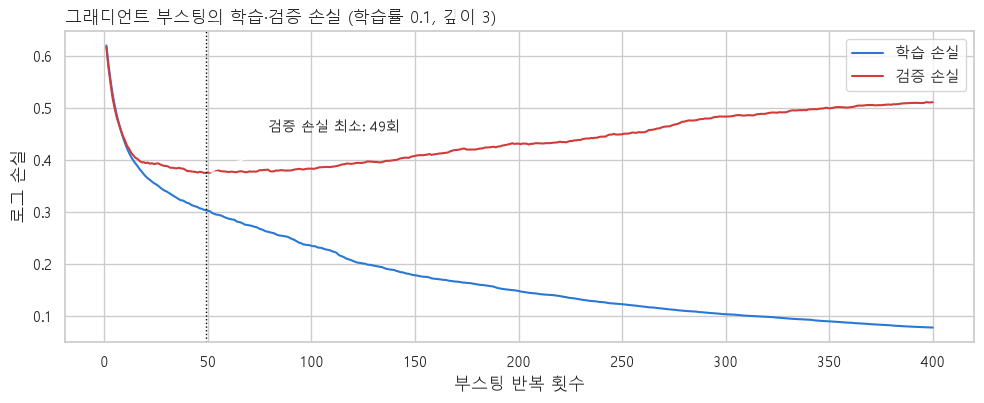

400회 반복 시 검증 손실 0.511 vs 최소 0.375 (49회)


In [15]:
X_t, X_v, y_t, y_v = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)
gb_demo = make_pipe(GradientBoostingClassifier(n_estimators=400, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE), None).fit(X_t, y_t)
prep_t = gb_demo[:-1].transform(X_t)
prep_v = gb_demo[:-1].transform(X_v)
train_loss = [log_loss(y_t, p) for p in gb_demo[-1].staged_predict_proba(prep_t)]
valid_loss = [log_loss(y_v, p) for p in gb_demo[-1].staged_predict_proba(prep_v)]
best_round = int(np.argmin(valid_loss)) + 1

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(range(1, 401), train_loss, color=BLUE, label="학습 손실")
ax.plot(range(1, 401), valid_loss, color=RED, label="검증 손실")
ax.axvline(best_round, color="black", linestyle=":", linewidth=1)
ax.annotate(f"검증 손실 최소: {best_round}회", (best_round, min(valid_loss)), xytext=(best_round + 30, min(valid_loss) + 0.08),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("부스팅 반복 횟수")
ax.set_ylabel("로그 손실")
ax.set_title("그래디언트 부스팅의 학습·검증 손실 (학습률 0.1, 깊이 3)", loc="left")
ax.legend()
plt.tight_layout()
plt.show()
print(f"400회 반복 시 검증 손실 {valid_loss[-1]:.3f} vs 최소 {min(valid_loss):.3f} ({best_round}회)")

검증 손실이 가장 작은 지점을 지나 계속 반복하면 학습 데이터에만 맞춰집니다. 튜닝에서 **반복 횟수와 학습률을 함께** 탐색하고, 실무에서 **조기 종료**를 쓰는 이유입니다.

### 3-2. 앙상블: Soft Voting과 Stacking

In [16]:
members = [("lr", tuned["로지스틱 회귀"]), ("rf", tuned["랜덤 포레스트"]), ("gb", tuned["그래디언트 부스팅"]), ("xgb", tuned["XGBoost"])]
ensembles = {
    "Soft Voting": VotingClassifier(members, voting="soft"),
    "Stacking": StackingClassifier(members, final_estimator=LogisticRegression(max_iter=2000), cv=5),
}
ens_rows = []
for name, model in ensembles.items():
    s = cross_validate(model, X_dev, y_dev, cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)
    ens_rows.append({"모델": name, "중첩 CV": s["test_score"].mean(), "표준편차": s["test_score"].std(),
                     "학습-CV 차이": s["train_score"].mean() - s["test_score"].mean()})
ens_table = pd.DataFrame(ens_rows).set_index("모델")
ens_table.style.format({"중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})

,중첩 CV,표준편차,학습-CV 차이
모델,,,
Soft Voting,0.826,0.017,+0.085
Stacking,0.831,0.016,+0.067


앙상블의 구성 모델 설정은 개발 데이터 전체로 고른 값이라, 위 점수는 단일 모델의 중첩 CV보다 약간 낙관적일 수 있습니다.

평균 점수가 비슷해도 **맞히는 승객은 다를 수 있습니다.** Soft Voting과 최고 단일 모델이 각각 어떤 승객을 새로 맞히고 놓치는지 비교했습니다.

In [17]:
best_single = tuned_table.index[0]
oof_single = cross_val_predict(tuned[best_single], X_dev, y_dev, cv=cv, n_jobs=-1)
oof_vote = cross_val_predict(ensembles["Soft Voting"], X_dev, y_dev, cv=cv, n_jobs=-1)
fixed = ((oof_vote == y_dev) & (oof_single != y_dev)).sum()
broken = ((oof_vote != y_dev) & (oof_single == y_dev)).sum()
print(f"기준: {best_single} (OOF 정답 {(oof_single == y_dev).sum()}명) vs Soft Voting (OOF 정답 {(oof_vote == y_dev).sum()}명)")
print(f"Voting만 맞힘 {fixed}명 · Voting만 틀림 {broken}명 → 순변화 {fixed - broken:+d}명")

기준: 로지스틱 회귀 (OOF 정답 591명) vs Soft Voting (OOF 정답 588명)
Voting만 맞힘 19명 · Voting만 틀림 22명 → 순변화 -3명


---
## 4. 최종 모델 선택과 평가

점수 차이가 표준오차 안이라면 우연일 수 있습니다. 그래서 **1-SE 규칙**으로 최종 모델을 골랐습니다. 최고 점수에서 표준오차 1개 이내인 후보 중 **가장 단순한 모델**을 선택합니다.

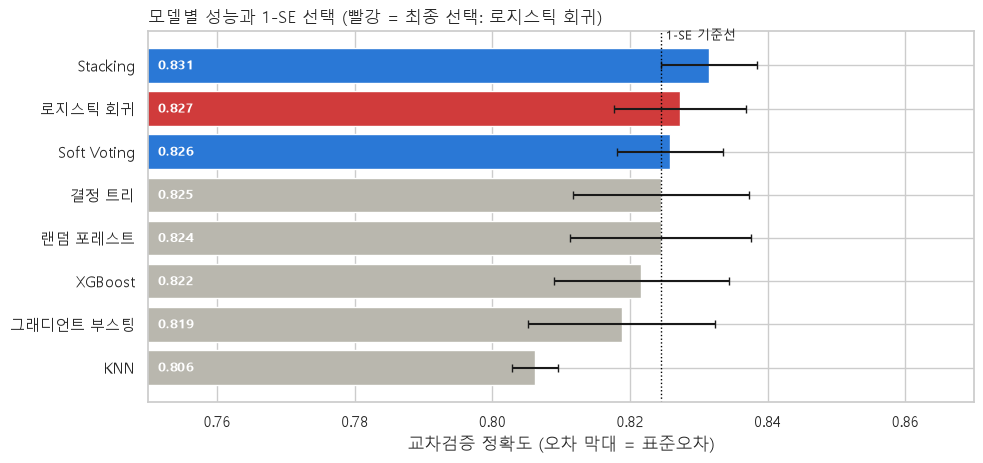

,중첩 CV,표준편차,학습-CV 차이,단순한 순서,1-SE 후보
모델,,,,,
Stacking,0.831,0.016,+0.067,8,✓
로지스틱 회귀,0.827,0.021,+0.016,1,✓
Soft Voting,0.826,0.017,+0.085,7,✓
결정 트리,0.825,0.029,+0.048,2,
랜덤 포레스트,0.824,0.029,+0.066,4,
XGBoost,0.822,0.028,+0.083,6,
그래디언트 부스팅,0.819,0.030,+0.091,5,
KNN,0.806,0.007,+0.032,3,


In [18]:
all_models = {**tuned, **ensembles}
summary = pd.concat([tuned_table[["중첩 CV", "표준편차", "학습-CV 차이"]], ens_table])
COMPLEXITY = ["로지스틱 회귀", "결정 트리", "KNN", "랜덤 포레스트", "그래디언트 부스팅", "XGBoost", "Soft Voting", "Stacking"]
summary["단순한 순서"] = [COMPLEXITY.index(m) + 1 for m in summary.index]
summary = summary.sort_values("중첩 CV", ascending=False)

top = summary.iloc[0]
cutoff = top["중첩 CV"] - top["표준편차"] / np.sqrt(cv.get_n_splits())
candidates = summary[summary["중첩 CV"] >= cutoff]
final_name = candidates["단순한 순서"].idxmin()
summary["1-SE 후보"] = np.where(summary["중첩 CV"] >= cutoff, "✓", "")

fig, ax = plt.subplots(figsize=(10, 4.8))
plot = summary.iloc[::-1]
colors = [RED if m == final_name else (BLUE if m in candidates.index else GRAY) for m in plot.index]
ax.barh(plot.index, plot["중첩 CV"], xerr=plot["표준편차"] / np.sqrt(5), color=colors, capsize=3)
ax.axvline(cutoff, color="black", linestyle=":", linewidth=1)
ax.text(cutoff, len(plot) - 0.4, " 1-SE 기준선", fontsize=9)
for i, v in enumerate(plot["중첩 CV"]):
    ax.text(0.7515, i, f"{v:.3f}", va="center", fontsize=9.5, color="white", fontweight="bold")
ax.set_xlim(0.75, 0.87)
ax.set_xlabel("교차검증 정확도 (오차 막대 = 표준오차)")
ax.set_title(f"모델별 성능과 1-SE 선택 (빨강 = 최종 선택: {final_name})", loc="left")
plt.tight_layout()
plt.show()
summary.style.format({"중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})

### 4-1. 최종 평가 데이터에서 한 번 확인

최종 모델: 로지스틱 회귀
교차검증 정확도 0.827 → 최종 평가 정확도 0.838 · ROC-AUC 0.870

              precision    recall  f1-score   support

          사망      0.852     0.891     0.871       110
          생존      0.812     0.754     0.782        69

    accuracy                          0.838       179
   macro avg      0.832     0.822     0.827       179
weighted avg      0.837     0.838     0.837       179



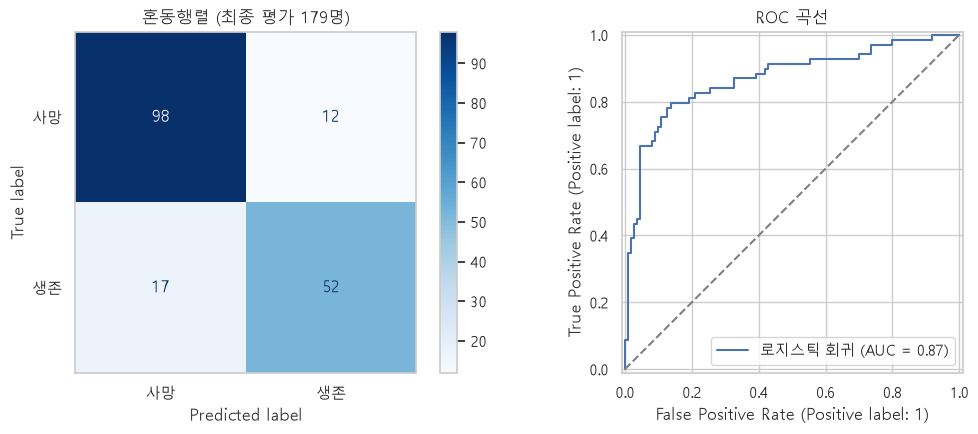

In [19]:
final_model = clone(all_models[final_name]).fit(X_dev, y_dev)
hold_pred = final_model.predict(X_hold)
hold_proba = final_model.predict_proba(X_hold)[:, 1]
print(f"최종 모델: {final_name}")
print(f"교차검증 정확도 {summary.loc[final_name, '중첩 CV']:.3f} → 최종 평가 정확도 {accuracy_score(y_hold, hold_pred):.3f} · ROC-AUC {roc_auc_score(y_hold, hold_proba):.3f}\n")
print(classification_report(y_hold, hold_pred, target_names=["사망", "생존"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_hold, hold_pred, display_labels=["사망", "생존"], cmap="Blues", ax=axes[0])
axes[0].set_title("혼동행렬 (최종 평가 179명)")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_hold, hold_proba, ax=axes[1], name=final_name)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC 곡선")
plt.tight_layout()
plt.show()

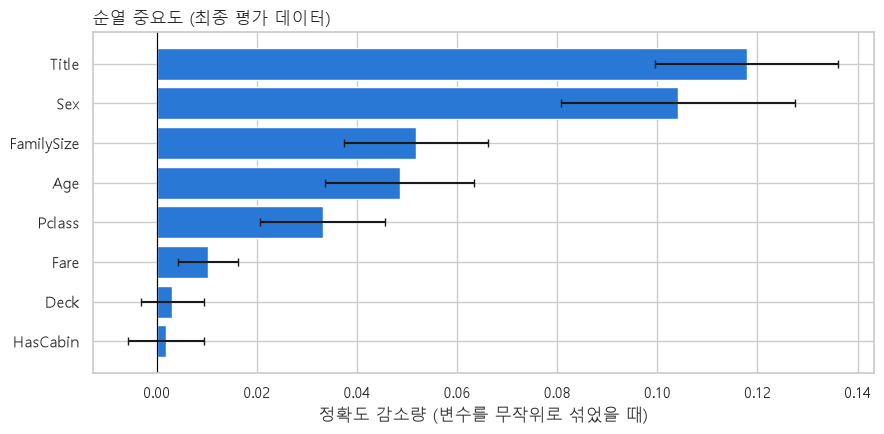

In [20]:
perm = permutation_importance(final_model, X_hold, y_hold, scoring="accuracy", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"평균": perm.importances_mean, "표준편차": perm.importances_std}, index=X_hold.columns).sort_values("평균")
imp = imp[imp["평균"].abs() > 0.001]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp["평균"], xerr=imp["표준편차"], color=BLUE, capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("정확도 감소량 (변수를 무작위로 섞었을 때)")
ax.set_title("순열 중요도 (최종 평가 데이터)", loc="left")
plt.tight_layout()
plt.show()

In [21]:
errors = holdout_fe.assign(예측=hold_pred, 생존확률=hold_proba.round(2), 오류=(hold_pred != y_hold).astype(int))
group_error = errors.groupby(["Sex", "Pclass"])["오류"].agg(오류율="mean", 인원="size")
display(group_error.style.format({"오류율": "{:.0%}"}).background_gradient(subset=["오류율"], cmap="Reds"))

confident_wrong = errors[errors["오류"].eq(1)].assign(확신도=lambda d: (d["생존확률"] - 0.5).abs()).nlargest(6, "확신도")
confident_wrong[["Name", "Sex", "Pclass", "Age", "Title", "FamilySize", "Survived", "예측", "생존확률"]]

,Name,Sex,Pclass,Age,Title,FamilySize,Survived,예측,생존확률
570,"Harris, Mr. George",male,2,62.0,Mr,1,1,0,0.05
297,"Allison, Miss. Helen Loraine",female,1,2.0,Miss,4,0,1,0.94
444,"Johannesen-Bratthammer, Mr. Bernt",male,3,NaN,Mr,1,1,0,0.07
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,3,27.0,Mr,1,1,0,0.08
804,"Hedman, Mr. Oskar Arvid",male,3,27.0,Mr,1,1,0,0.08
271,"Tornquist, Mr. William Henry",male,3,25.0,Mr,1,1,0,0.09


모델은 **"여성·고등급은 생존, 남성·3등급은 사망"**이라는 큰 규칙을 잘 배웠습니다. 대신 그 규칙의 **예외**를 가장 많이 틀립니다. 대표적으로 살아남은 남성과 사망한 3등급 여성입니다. 이 승객들은 이 데이터의 변수만으로는 구분할 단서가 거의 없습니다. 소수 사례에 맞춘 규칙을 추가하면 과적합되므로 억지로 고치지 않았습니다.

### 4-2. Kaggle 제출 파일

In [22]:
# Kaggle 대회 페이지의 test.csv를 같은 폴더에 두면 제출 파일을 만든다.
# 최종 모델은 개발 + 최종 평가 데이터 전체(891명)로 다시 학습한다.
test_path = Path("test.csv")
if test_path.exists():
    full_fe = add_features(data)
    submit_model = clone(all_models[final_name]).fit(full_fe[X_dev.columns], full_fe["Survived"])
    test_fe = add_features(pd.read_csv(test_path))
    submission = pd.DataFrame({"PassengerId": test_fe["PassengerId"], "Survived": submit_model.predict(test_fe[X_dev.columns]).astype(int)})
    submission.to_csv("submission.csv", index=False)
    print("submission.csv 저장:", submission.shape)
else:
    print("test.csv가 없어 제출 파일 생성을 건너뜁니다. (Kaggle Titanic 대회에서 내려받아 같은 폴더에 두면 실행됩니다)")

test.csv가 없어 제출 파일 생성을 건너뜁니다. (Kaggle Titanic 대회에서 내려받아 같은 폴더에 두면 실행됩니다)


---
## 5. 결론

| 항목 | 결과 |
| :-- | :-- |
| **최종 모델** | 로지스틱 회귀 (`C=1`, 표준화 + 원-핫 인코딩, 호칭 × 등급 나이 대치) |
| **교차검증 정확도** (중첩 CV, 개발 712명) | **0.827** ± 0.021 |
| **최종 평가 정확도** (179명, 한 번만 사용) | **0.838** · ROC-AUC 0.870 |

**1. 생존을 가른 요인**
- **호칭 · 성별**이 가장 중요하고(순열 중요도 0.12 · 0.10), **가족 규모 · 나이 · 객실 등급**이 뒤를 잇습니다.
- 여성 74% vs 남성 19%, 1등급 여성 97% vs 3등급 남성 13%로 **"여성과 아이 먼저" + 등급 차이**가 데이터에 그대로 나타납니다.

**2. 복잡한 모델이 항상 이기지 않는다**
- 랜덤 포레스트와 XGBoost는 설정을 고르는 CV에서 0.84로 가장 높았습니다. 하지만 **중첩 CV에서는 0.82대**로 내려갔습니다. 튜닝 점수에는 낙관 편향이 있다는 증거입니다.
- 최고 점수인 Stacking(0.831)과 로지스틱 회귀(0.827)의 차이는 **표준오차 안**입니다. 그래서 1-SE 규칙으로 **가장 단순하고 과적합이 가장 작은**(학습-CV 차이 +0.016) 로지스틱 회귀를 선택했습니다.
- Soft Voting은 로지스틱 회귀보다 19명을 더 맞혔지만 22명을 새로 틀려 **순변화는 -3명**입니다. 앙상블은 자동으로 개선되지 않습니다.

**3. 일반화 확인**
- 최종 평가 정확도(0.838)가 교차검증 추정(0.827)과 비슷합니다. 개발 데이터에 과적합되지 않았습니다.
- 다만 최종 평가 데이터가 179명이라 한 명의 차이가 0.56%p입니다. 이 정도 차이는 우연 범위 안입니다.

**한계와 다음 단계**
- 남은 오류는 대부분 **규칙의 예외**입니다. 살아남은 1등급 남성(오류율 30%)과 사망한 3등급 여성(29%)이 대표적이며, 현재 변수만으로는 구분할 단서가 부족합니다.
- 같은 티켓을 공유한 일행의 생존 여부처럼 **그룹 단위 정보**가 다음 개선 후보입니다. 다만 교차검증 안에서 계산해야 누수가 생기지 않습니다.
- Kaggle `test.csv`는 이 저장소에 포함하지 않아 리더보드 점수는 기록하지 않았습니다. 파일을 두면 제출 파일이 생성됩니다.